### A.	Explain the main assumptions of Linear Regression in detail.

##### Main assumptions of Linear Regression:

##### Linearity
##### The relationship between the independent variables (\(X\)) and the dependent variable (\(Y\)) is linear in parameters. This means the change in \(Y\) associated with a one-unit change in \(X\) is constant, forming a straight-line trend

##### Homoscedasticity
##### The variance of the error terms is constant across all levels of the independent variables

##### Normality of Residuals
##### The error terms are normally distributed around a mean of zero.

##### Lack of Multicollinearity
##### In multiple linear regression, the independent variables are not overly or linearly correlated with each other

### B.	What is the difference between R-squared and Adjusted R-squared?

R-squared measures the proportion of variance in the dependent variable explained the model's independent variables, while adjusted R-squared modifies that measurement by penalizing the addition of irrelevant predictors.

Key Differences

• Behavior with New Variables:
	• R-squared: Always increases or stays the same when you add a new predictor, even if the variable has no real relationship to the outcome.
    
    • Adjusted R-squared: Only increases if the new variable improves the model more than would be expected by chance; otherwise, it decreases.

• Value Range:
    • R-squared: Always falls between \(0\) and \(1\) (or 0% and 100%).
    
    • Adjusted R-squared: Can be lower than R-squared and can occasionally drop below zero if the model is a poor fit for the sample size.

• Best Use Case:
    • R-squared: Useful for simple linear regression or getting a quick sense of how well a model fits your data.
    
    • Adjusted R-squared: Essential for multiple regression and comparing models that have different numbers of independent variables.


Formulas

• R-squared
R^2 = 1 - (Sum of Squared Residuals/Sum of Squares)

• Adjusted-R squared

1 - ((1-R^2)*(n-1)/(n-k-1))

(Where \(n\) is the sample size and \(k\) is the number of independent variables)

#### C.	What are the different types of Regularization techniques in Regression. Explain in detail with cost functions of each technique.

Regularization is a technique used in machine learning to reduce overfitting, control model complexity, and improve the model's ability to generalize to unseen data.

In regression, a model learns the relationship between independent variables (\(X\)) and a dependent variable (\(y\)). Sometimes, it learns the training data too closely, including noise and irrelevant patterns. Regularization addresses this by adding a penalty term to the original cost function, discouraging overly complex models.

Main types of regularization in regression
L1


1. Ridge Regression

Uses squared coefficients. Shrinks coefficients toward zero but generally does not make them exactly zero.

J= MSE + lambda (sum_{j=1}^{p}\beta_j^2)
2. Lasso Regression

Uses the absolute values of coefficients. Can shrink some coefficients exactly to zero, performing feature selection.


L1+L2

3. Elastic Net Regression

Combines L1 and L2 penalties, balancing feature selection with coefficient shrinkage.


In [200]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

In [201]:
mobile_data = pd.read_csv('Cellphone.csv')

In [202]:
mobile_data.head(10)

,Product_id,Price,Sale,weight,resoloution,ppi,cpu core,cpu freq,internal mem,ram,RearCam,Front_Cam,battery,thickness
0,203,2357,10,135.0,5.2,424,8,1.35,16.0,3.000,13.00,8.0,2610,7.4
1,880,1749,10,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
2,40,1916,10,110.0,4.7,312,4,1.20,8.0,1.500,13.00,5.0,2000,7.6
3,99,1315,11,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
4,880,1749,11,125.0,4.0,233,2,1.30,4.0,1.000,3.15,0.0,1700,9.9
5,947,2137,12,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
6,774,1238,13,134.1,4.0,233,2,1.20,8.0,1.000,2.00,0.0,1560,11.7
7,947,2137,13,150.0,5.5,401,4,2.30,16.0,2.000,16.00,8.0,2500,9.5
8,99,1315,14,118.5,4.0,233,2,1.30,4.0,0.512,3.15,0.0,1400,11.0
9,1103,2580,15,145.0,5.1,432,4,2.50,16.0,2.000,16.00,2.0,2800,8.1


In [203]:
mobile_data.rename(
    columns={
        'internal mem': 'internal_mem',
        'cpu core': 'cpu_core',
        'cpu freq': 'cpu_freq'
    },
    inplace=True
)

C:\Users\abhin\AppData\Local\Temp\ipykernel_28736\751235335.py:1: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mobile_data.rename(


In [204]:
mobile_data.shape

(161, 14)

In [205]:
mobile_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Product_id    161 non-null    int64  
 1   Price         161 non-null    int64  
 2   Sale          161 non-null    int64  
 3   weight        161 non-null    float64
 4   resoloution   161 non-null    float64
 5   ppi           161 non-null    int64  
 6   cpu_core      161 non-null    int64  
 7   cpu_freq      161 non-null    float64
 8   internal_mem  161 non-null    float64
 9   ram           161 non-null    float64
 10  RearCam       161 non-null    float64
 11  Front_Cam     161 non-null    float64
 12  battery       161 non-null    int64  
 13  thickness     161 non-null    float64
dtypes: float64(8), int64(6)
memory usage: 17.7 KB


In [206]:
mobile_data.describe()

,Product_id,Price,Sale,weight,resoloution,ppi,cpu_core,cpu_freq,internal_mem,ram,RearCam,Front_Cam,battery,thickness
count,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000,161.000000
mean,675.559006,2215.596273,621.465839,170.426087,5.209938,335.055901,4.857143,1.502832,24.501714,2.204994,10.378261,4.503106,2842.111801,8.921739
std,410.851583,768.187171,1546.618517,92.888612,1.509953,134.826659,2.444016,0.599783,28.804773,1.609831,6.181585,4.342053,1366.990838,2.192564
min,10.000000,614.000000,10.000000,66.000000,1.400000,121.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,800.000000,5.100000
25%,237.000000,1734.000000,37.000000,134.100000,4.800000,233.000000,4.000000,1.200000,8.000000,1.000000,5.000000,0.000000,2040.000000,7.600000
50%,774.000000,2258.000000,106.000000,153.000000,5.150000,294.000000,4.000000,1.400000,16.000000,2.000000,12.000000,5.000000,2800.000000,8.400000
75%,1026.000000,2744.000000,382.000000,170.000000,5.500000,428.000000,8.000000,1.875000,32.000000,3.000000,16.000000,8.000000,3240.000000,9.800000
max,1339.000000,4361.000000,9807.000000,753.000000,12.200000,806.000000,8.000000,2.700000,128.000000,6.000000,23.000000,20.000000,9500.000000,18.500000


In [207]:
mobile_data.isnull().sum()

Product_id      0
Price           0
Sale            0
weight          0
resoloution     0
ppi             0
cpu_core        0
cpu_freq        0
internal_mem    0
ram             0
RearCam         0
Front_Cam       0
battery         0
thickness       0
dtype: int64

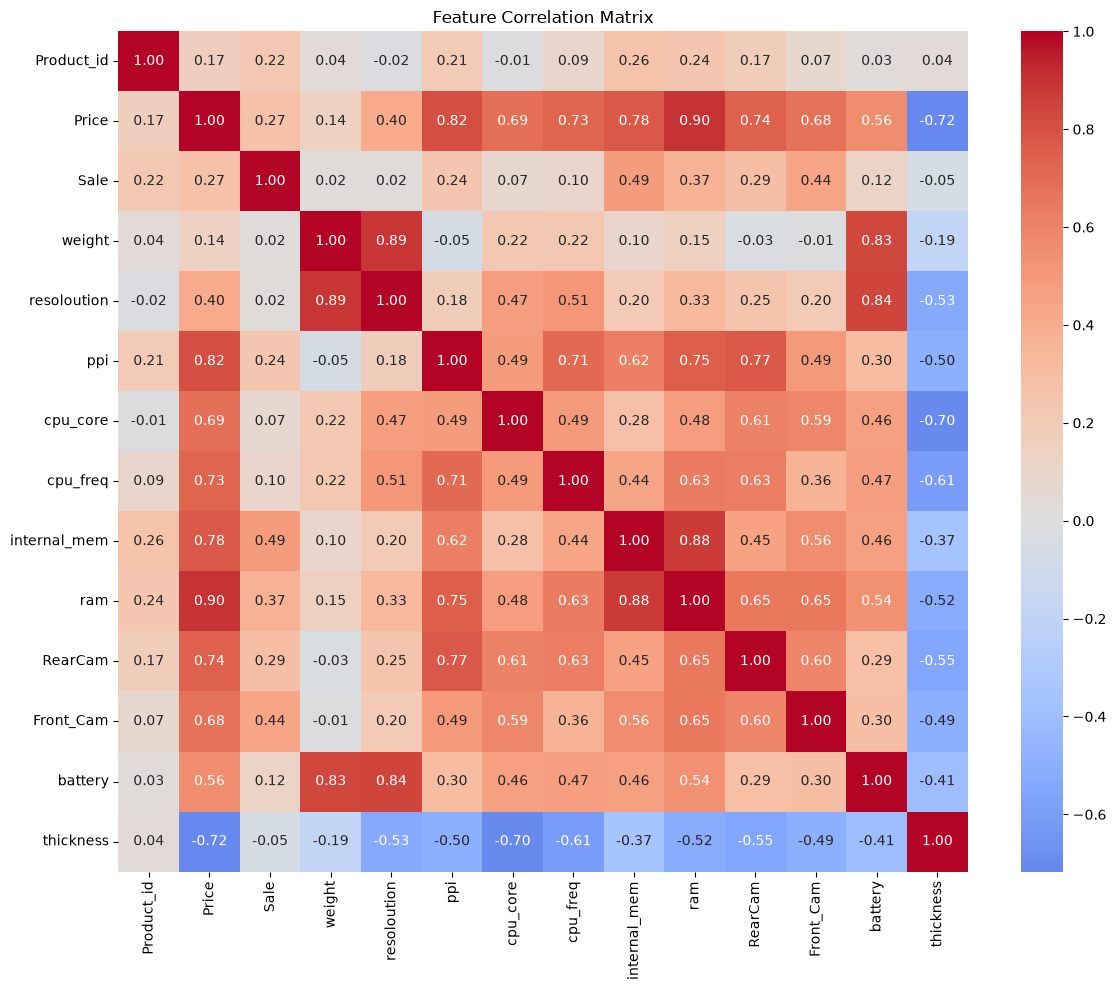

Price           1.000000
ram             0.896915
ppi             0.817614
internal_mem    0.776738
RearCam         0.739538
cpu_freq        0.727383
cpu_core        0.686811
Front_Cam       0.675286
battery         0.559946
resoloution     0.404010
Sale            0.273263
Product_id      0.165136
weight          0.144555
thickness      -0.716773
Name: Price, dtype: float64

In [208]:
correlations = mobile_data.corr(numeric_only=True)

plt.figure(figsize=(12, 10))
sns.heatmap(correlations, cmap='coolwarm', center=0, annot=True, fmt='.2f')
plt.title('Feature Correlation Matrix')
plt.tight_layout()
plt.show()

correlations['Price'].sort_values(ascending=False)

In [209]:
## 'sale', 'product_id', 'resolution' and 'weight' are weekly correlated hence dropping them 

In [210]:
mobile_data.drop(columns=['Sale', 'Product_id', 'weight', 'resoloution'], inplace=True)

C:\Users\abhin\AppData\Local\Temp\ipykernel_28736\3432954785.py:1: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  mobile_data.drop(columns=['Sale', 'Product_id', 'weight', 'resoloution'], inplace=True)


In [211]:
mobile_data.info()

<class 'pandas.DataFrame'>
RangeIndex: 161 entries, 0 to 160
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Price         161 non-null    int64  
 1   ppi           161 non-null    int64  
 2   cpu_core      161 non-null    int64  
 3   cpu_freq      161 non-null    float64
 4   internal_mem  161 non-null    float64
 5   ram           161 non-null    float64
 6   RearCam       161 non-null    float64
 7   Front_Cam     161 non-null    float64
 8   battery       161 non-null    int64  
 9   thickness     161 non-null    float64
dtypes: float64(6), int64(4)
memory usage: 12.7 KB


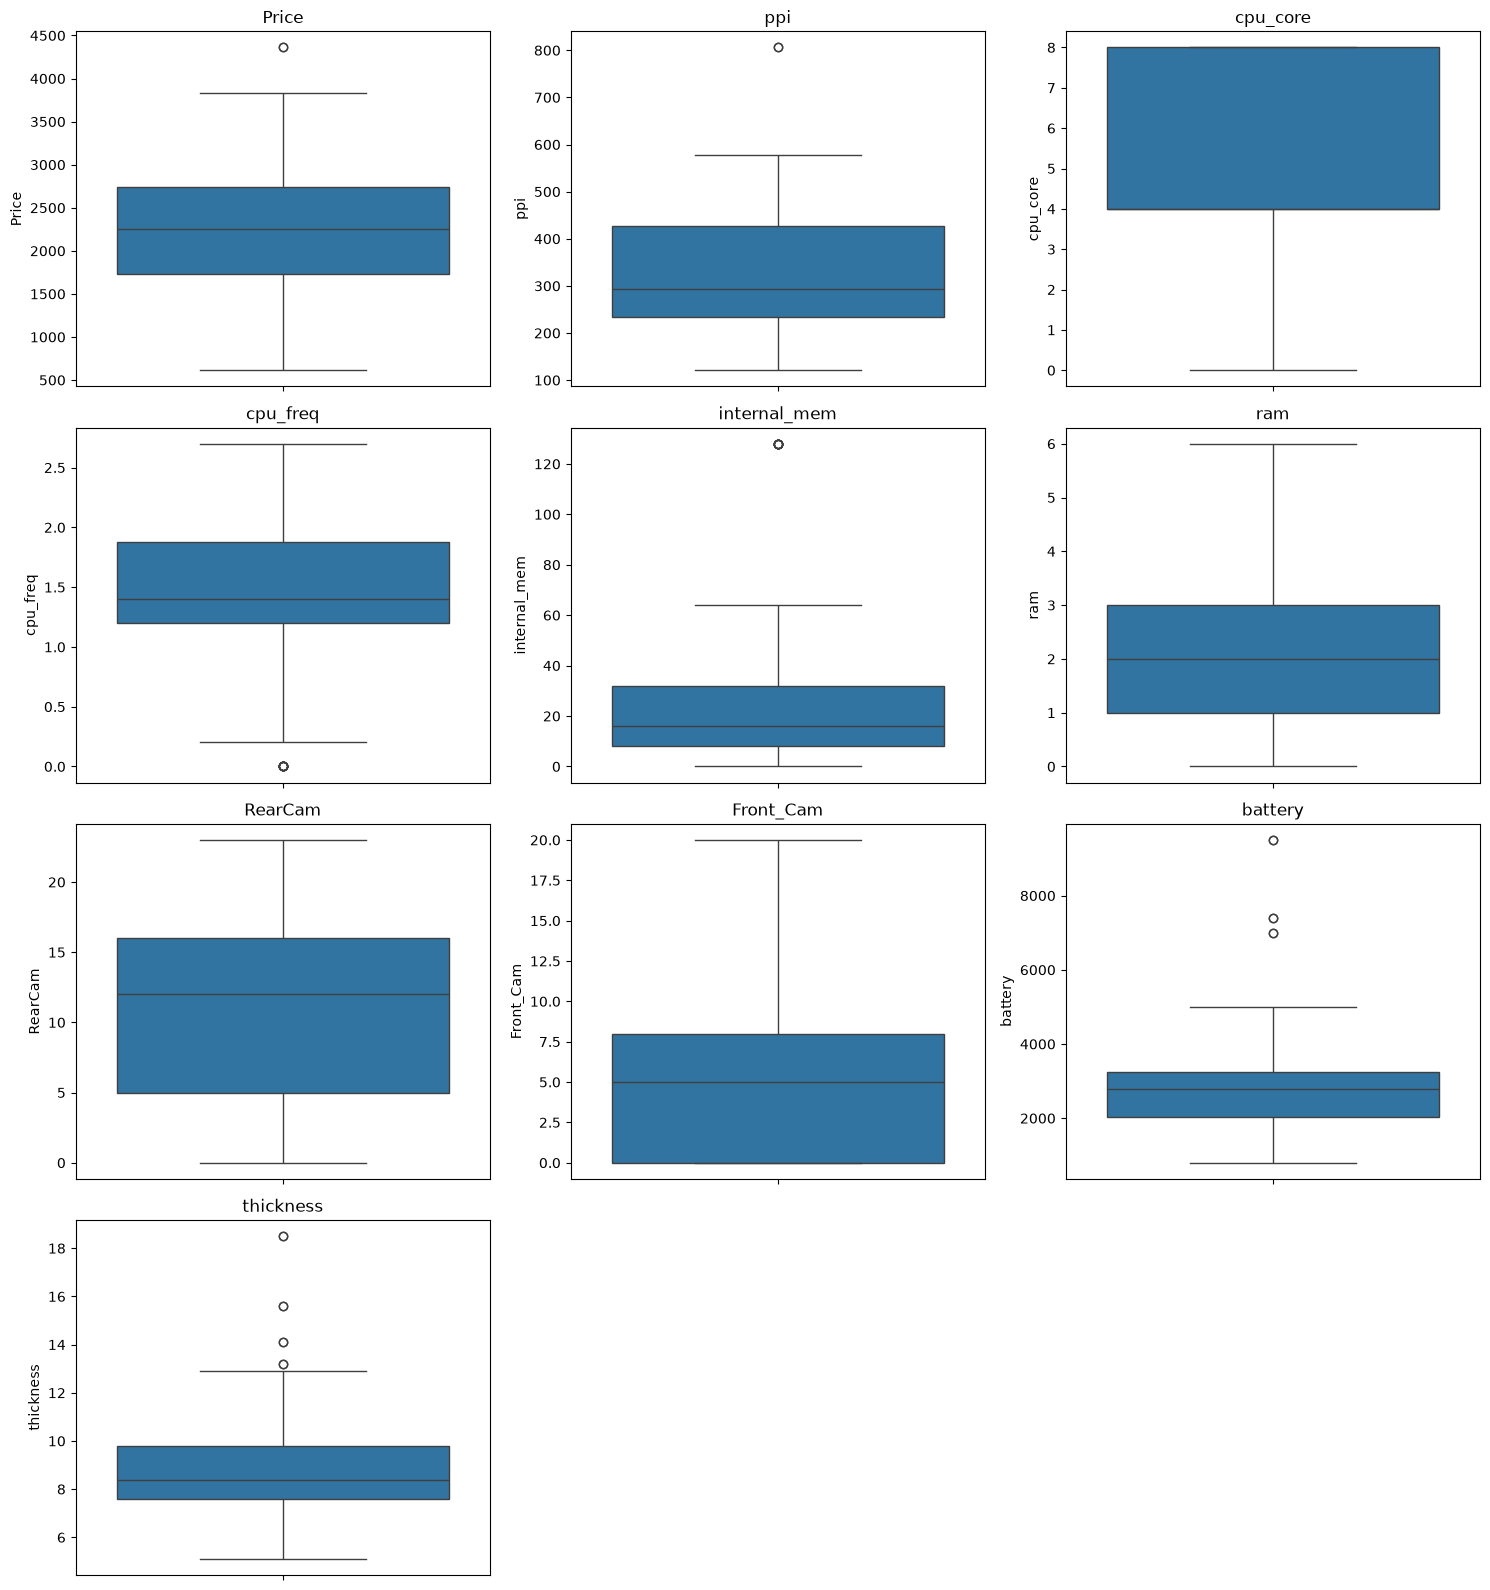

In [212]:
# Draw one boxplot per feature so differences in scale don't obscure the plots.
features = mobile_data.columns
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).flatten()

for ax, feature in zip(axes, features):
    sns.boxplot(y=mobile_data[feature], ax=ax)
    ax.set_title(feature)

for ax in axes[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()

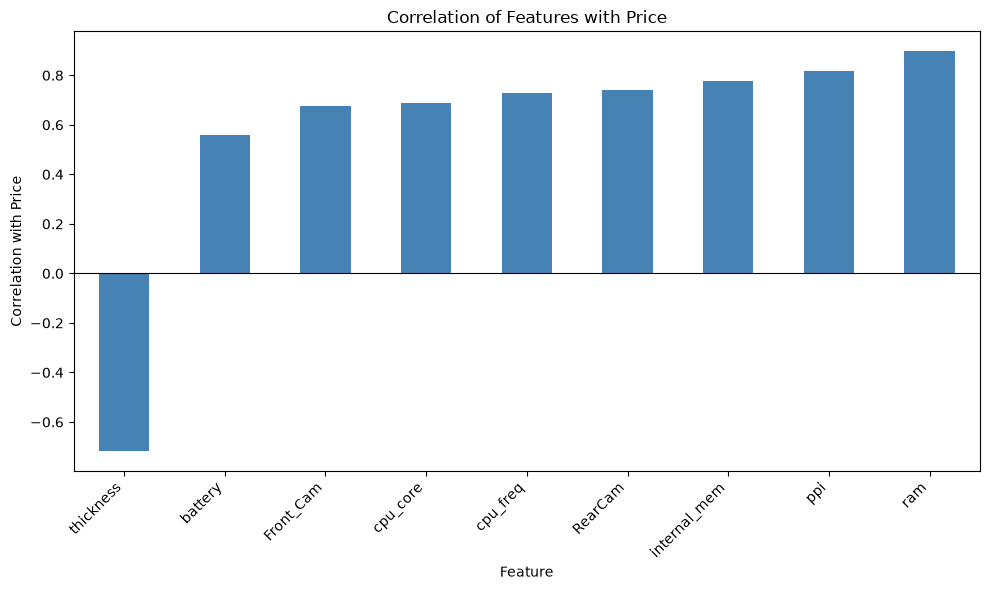

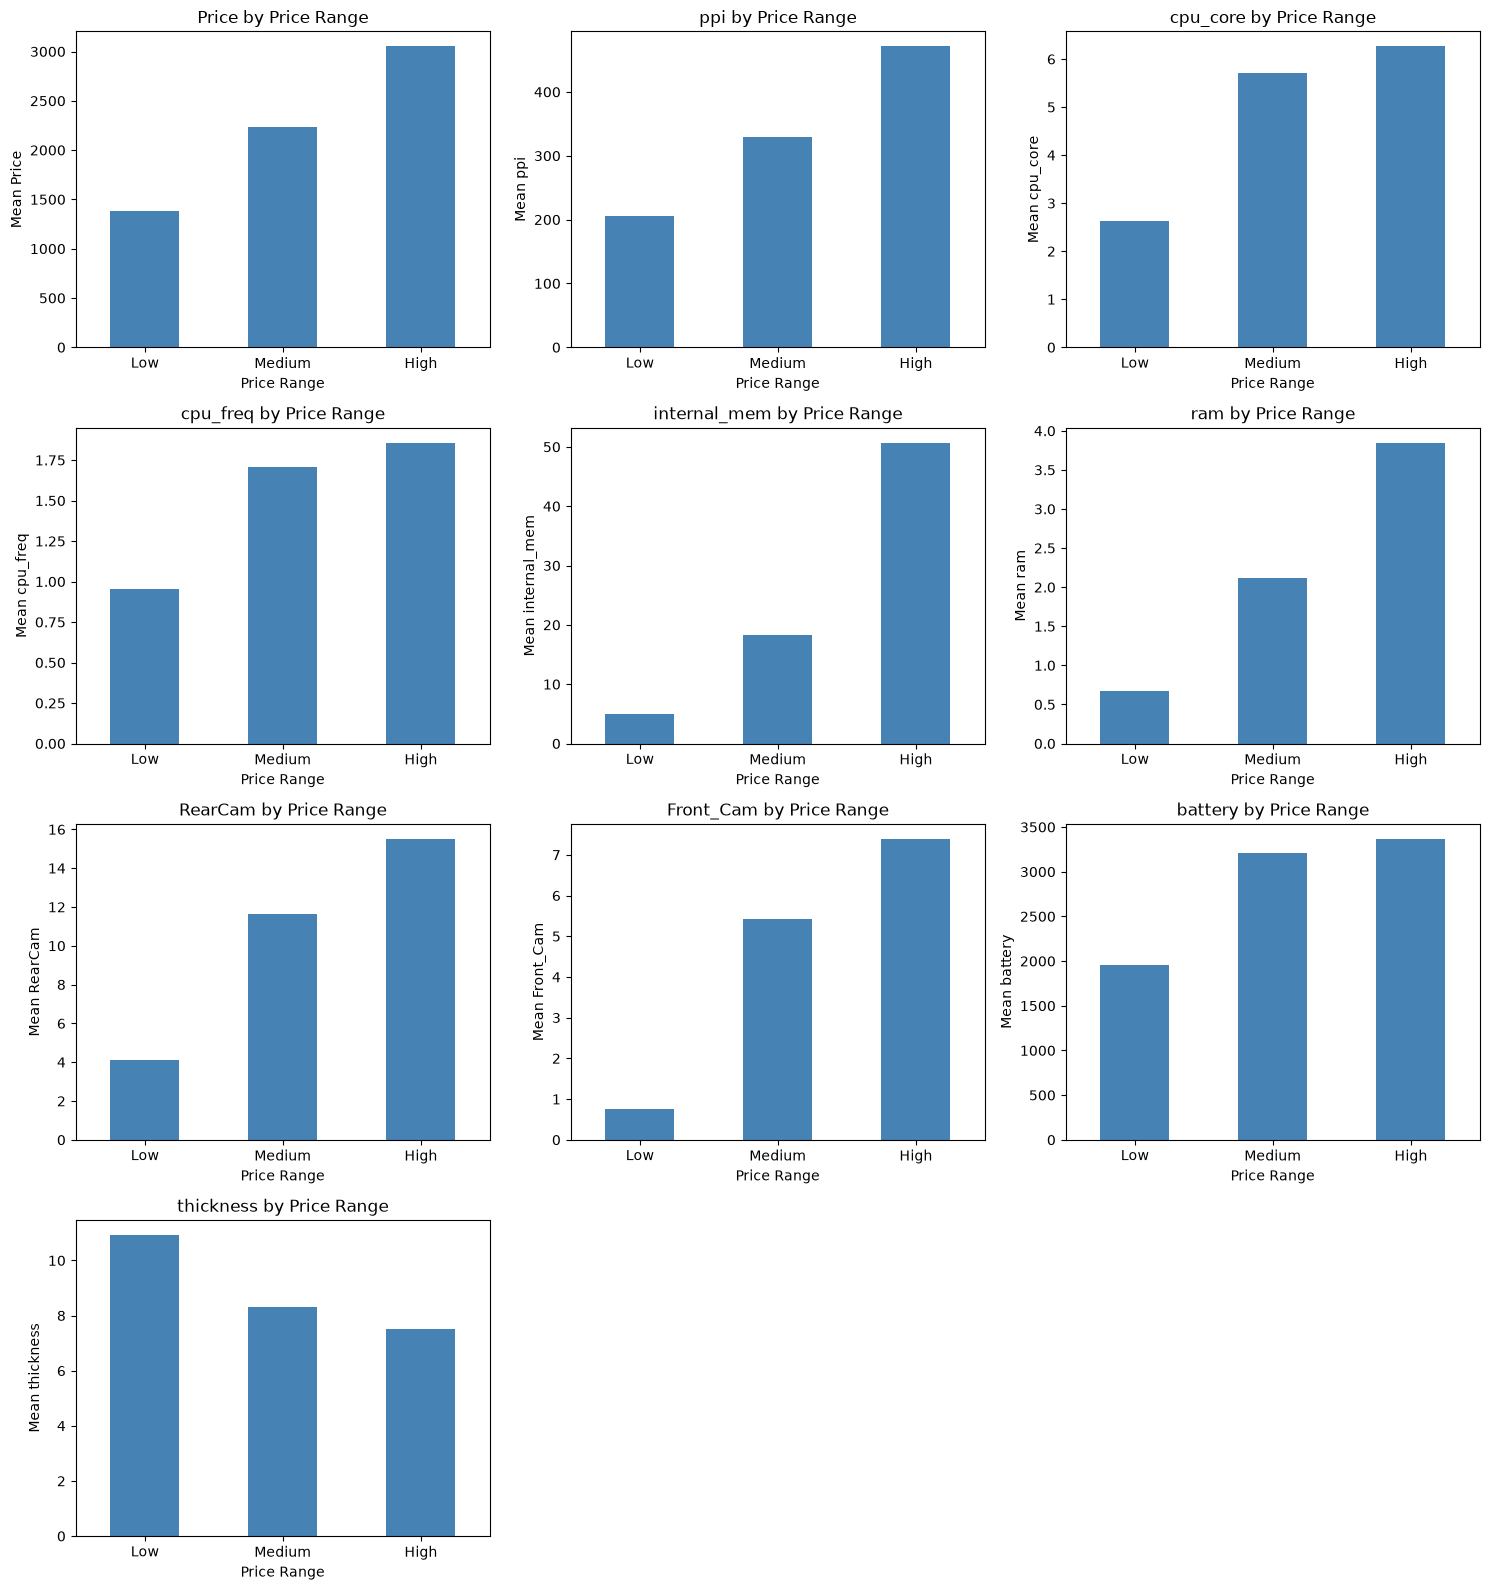

In [213]:
price_correlations = (
    mobile_data.corr(numeric_only=True)['Price']
    .drop('Price')
    .sort_values()
)

plt.figure(figsize=(10, 6))
price_correlations.plot(kind='bar', color='steelblue')
plt.title('Correlation of Features with Price')
plt.xlabel('Feature')
plt.ylabel('Correlation with Price')
plt.axhline(0, color='black', linewidth=0.8)
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
price_order = ['Low', 'Medium', 'High']
data_for_plot = mobile_data.copy()

data_for_plot['Price_range'] = pd.qcut(
    data_for_plot['Price'],
    q=3,
    labels=price_order
)

features = mobile_data.columns
n_cols = 3
n_rows = int(np.ceil(len(features) / n_cols))

fig, axes = plt.subplots(n_rows, n_cols, figsize=(15, 4 * n_rows))
axes = np.array(axes).flatten()

for ax, feature in zip(axes, features):
    means = data_for_plot.groupby('Price_range', observed=False)[feature].mean()
    means.reindex(price_order).plot(kind='bar', ax=ax, color='steelblue')
    ax.set_title(f'{feature} by Price Range')
    ax.set_xlabel('Price Range')
    ax.set_ylabel(f'Mean {feature}')
    ax.tick_params(axis='x', rotation=0)

for ax in axes[len(features):]:
    ax.remove()

plt.tight_layout()
plt.show()

In [214]:
# Check skewness of the features to decide if any transformation is needed
skewness = mobile_data.skew(numeric_only=True)
skewness = skewness.sort_values(key=lambda s: s.abs(), ascending=False)

skewness

internal_mem    2.389683
battery         2.092660
thickness       1.587680
Front_Cam       1.169750
ram             0.792698
ppi             0.602503
cpu_freq       -0.512663
RearCam         0.106929
Price           0.052347
cpu_core       -0.009077
dtype: float64

In [215]:
## check skewness of the features to see if any transformation is needed

In [216]:
skew_check = skewness.to_frame(name='skewness')
skew_check['assessment'] = np.select(
    [skew_check['skewness'].abs() > 1,
     skew_check['skewness'].abs() > 0.5],
    ['Strong skew: consider transformation',
     'Moderate skew: review'],
    default='Little skew: transformation likely unnecessary'
)

skew_check

,skewness,assessment
internal_mem,2.389683,Strong skew: consider transformation
battery,2.092660,Strong skew: consider transformation
thickness,1.587680,Strong skew: consider transformation
Front_Cam,1.169750,Strong skew: consider transformation
ram,0.792698,Moderate skew: review
ppi,0.602503,Moderate skew: review
cpu_freq,-0.512663,Moderate skew: review
RearCam,0.106929,Little skew: transformation likely unnecessary
Price,0.052347,Little skew: transformation likely unnecessary
cpu_core,-0.009077,Little skew: transformation likely unnecessary


In [217]:
## split the data into features and target variable

In [218]:
X = mobile_data.drop(columns='Price')
y = mobile_data['Price']
X_train_raw, X_test_raw, y_train_scaled, y_test_scaled = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [219]:
## perform feature scaling using StandardScaler

In [220]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train_scaled = pd.DataFrame(
    scaler.fit_transform(X_train_raw),
    columns=X.columns,
    index=X_train_raw.index
)
X_test_scaled = pd.DataFrame(
    scaler.transform(X_test_raw),
    columns=X.columns,
    index=X_test_raw.index
)

X_train_scaled

,ppi,cpu_core,cpu_freq,internal_mem,ram,RearCam,Front_Cam,battery,thickness
115,1.303784,-0.360680,0.700967,0.246710,1.121291,0.919051,0.070159,0.289210,-0.585008
2,-0.150404,-0.360680,-0.465309,-0.570668,-0.435058,0.443103,0.070159,-0.629752,-0.585008
123,-0.541081,-0.360680,-0.465309,-0.298209,-0.123788,-0.350144,-0.832388,0.442370,0.544944
45,-0.280630,-0.360680,-0.292527,-0.298209,-0.123788,0.443103,0.070159,-0.246851,-0.106952
42,-0.830472,-0.360680,-0.292527,-0.570668,-0.746328,-0.826093,-1.058025,-0.936072,0.501484
...,...,...,...,...,...,...,...,...,...
71,-0.280630,1.259216,0.053036,-0.298209,-0.123788,0.443103,0.070159,-0.400011,-0.498089
106,0.775646,1.259216,-0.378918,-0.298209,-0.123788,0.919051,0.747069,-0.093691,-0.411170
14,0.717768,-0.360680,1.780852,-0.298209,-0.123788,0.919051,-0.606751,-0.017111,-0.367710
92,-0.280630,-0.360680,-0.465309,-0.570668,-0.746328,0.443103,0.070159,-0.553172,-0.237331


In [221]:
## Creating linear regression model and evaluating its performance

In [222]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

linear_model = LinearRegression()
linear_model.fit(X_train_scaled, y_train_scaled)

y_pred = linear_model.predict(X_test_scaled)

print(f"R²: {r2_score(y_test_scaled, y_pred):.3f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test_scaled, y_pred)):.2f}")

R²: 0.949
RMSE: 169.40


In [223]:
from sklearn.linear_model import Ridge, Lasso, ElasticNet

models = {
    "Ridge": Ridge(),
    "Lasso": Lasso(max_iter=10000),
    "Elastic Net": ElasticNet(max_iter=10000)
}

for name, model in models.items():
    model.fit(X_train_scaled, y_train_scaled)
    predictions = model.predict(X_test_scaled)

    r2 = r2_score(y_test_scaled, predictions)
    rmse = np.sqrt(mean_squared_error(y_test_scaled, predictions))

    print(f"{name}: R² = {r2:.3f}, RMSE = {rmse:.2f}")

Ridge: R² = 0.949, RMSE = 169.53
Lasso: R² = 0.949, RMSE = 169.92
Elastic Net: R² = 0.923, RMSE = 209.26


In [224]:
## Model Performance Comparison

## Linear Regression, Ridge, Lasso, and Elastic Net were trained on the same scaled training features and evaluated on the same test set. Performance is compared using **R²** and **RMSE**.

## - **Higher R²** indicates that the model explains more variation in phone prices.
## - **Lower RMSE** indicates smaller prediction errors, in the same units as `Price`.

## The model with the highest R² and lowest RMSE performs best on this test set. Regularized models may help reduce overfitting by penalizing large coefficients. Note that the target values were not scaled; `y_train_scaled` and `y_test_scaled` are simply variable names.

### Hence we can say that the 'Liner Regression' is the best model to be deployed for this training and testing dataset among Linear Regression Family.

In [225]:
## creating the pickle files for the model and the scaler to be used in the web application

import pickle
import joblib

joblib.dump(linear_model, 'mobile_price_model.pkl')
joblib.dump(scaler, 'scaler.pkl')

['scaler.pkl']